# Previsão e estoque perecível

Estudo independente com dados sintéticos e assistência de IA. Células executadas; sem dados privados, rede ou modelos binários de terceiros. A explicação aprofundada está em `docs/EXPLICACAO_COMPLETA.md`. Reexecute em uma sessão nova.

In [1]:
from pathlib import Path
import sys, json, contextlib, io
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.pipeline import *
from IPython.display import display, Image
print('Seed:', SEED)

Seed: 20261111


## Executar a implementação

O notebook importa as mesmas funções usadas no pipeline e no painel. O stdout completo pode ser consultado pela execução no terminal; aqui mostramos os indicadores relevantes.

In [2]:
buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    result = run()
print(json.dumps(result['environment'], indent=2))

{
  "python": "3.10.12",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "matplotlib": "3.10.9",
  "seed": 20261111
}


## Contrato dos dados

Cada linha é dia/item observado. Domingo fechado é zero conhecido; dia ausente é rejeitado. Vendas iguais à demanda são uma hipótese do gerador, não um fato garantido em caixa real.

In [3]:
daily=validate_daily(generate())
display(daily.head(14))
print('Dias:', daily.date.nunique(), 'Registros:', len(daily))
assert (daily.loc[~daily.is_open,'quantity']==0).all()

,date,item,quantity,is_open,observed
0,2024-01-01,Cafe com leite,60,True,True
1,2024-01-01,Cappuccino,35,True,True
2,2024-01-02,Cafe com leite,45,True,True
3,2024-01-02,Cappuccino,36,True,True
4,2024-01-03,Cafe com leite,60,True,True
5,2024-01-03,Cappuccino,36,True,True
6,2024-01-04,Cafe com leite,61,True,True
7,2024-01-04,Cappuccino,38,True,True
8,2024-01-05,Cafe com leite,72,True,True
9,2024-01-05,Cappuccino,45,True,True


Dias: 600 Registros: 1200


## Escolha antes do teste

460 dias iniciais,84 de validação e56 de teste. A emissão é semanal: sete dias de uma vez, sem observar o futuro dentro da semana. Na próxima origem, os dias passados podem entrar no histórico.

,Cafe com leite,Cappuccino
seasonal7,5.023810,4.666667
moving7,19.540816,12.717687
ses025,19.156704,12.593296


,item,mae_units,wape
0,Cafe com leite,5.178571,0.080533
1,Cappuccino,4.428571,0.114075


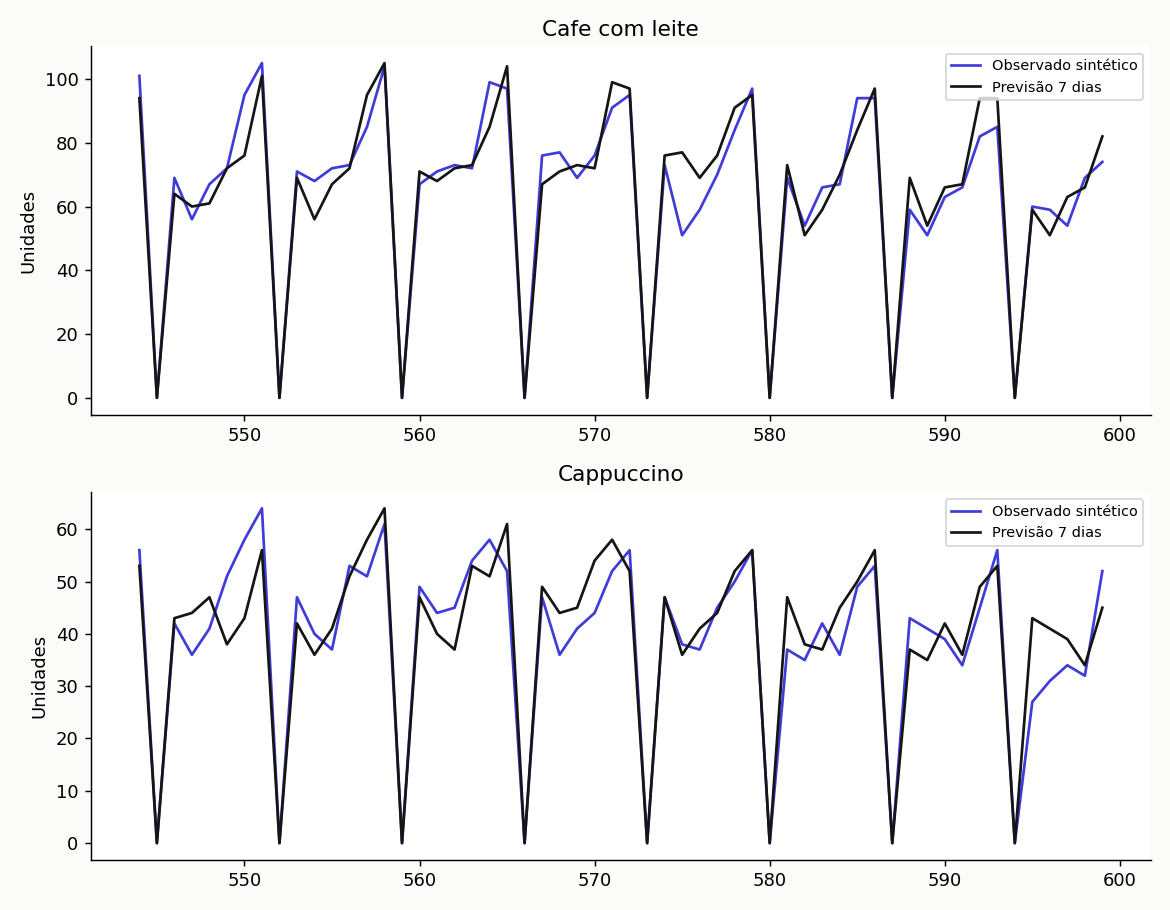

In [4]:
display(pd.DataFrame({item: data['validation_mae'] for item,data in result['selections'].items()}))
display(pd.DataFrame(result['performance']))
display(Image(filename=str(outdir()/'forecast.png')))

## Contas manuais de previsão e ficha

A previsão sazonal repete a semana; a média móvel perde o padrão entre dias.10 cafés com leite e5 cappuccinos precisam de1700ml.

In [5]:
assert list(forecast([10,20,30,40,50,60,0],7,'seasonal7')) == [10,20,30,40,50,60,0]
assert 10*RECIPES_ML['Cafe com leite']+5*RECIPES_ML['Cappuccino'] == 1700
print(levels(100,0,Policy(lead_days=2)))

{'rop_ml': 200, 'target_ml': 300, 'safety_ml': 0}


## Sem conhecer amanhã

Alterar o futuro não pode mudar a previsão já emitida. O teste abaixo é pequeno para poder inspecionar o resultado.

In [6]:
y=np.arange(60,dtype=float)
a=backtest(y,28,42,'moving7')
y[35:]=99999
b=backtest(y,28,42,'moving7')
np.testing.assert_array_equal(a.loc[a.origin==28,'prediction'],b.loc[b.origin==28,'prediction'])
print('Previsão da primeira origem não mudou')

Previsão da primeira origem não mudou


## Ordem dos eventos e conservação

Receber, expirar, atender por vencimento e decidir a compra. Falta é demanda perdida, sem backlog. Comprado deve aparecer como consumo, descarte, estoque final ou trânsito.

In [7]:
res,trace=simulate([500,0,2000,0,0,0,5000,0,20],500,100,Policy())
display(trace)
display(pd.DataFrame([res]))
assert res['purchased_ml'] == trace.served_ml.sum()+res['waste_ml']+res['end_onhand_ml']+res['end_pipeline_ml']

,day,demand_ml,arrival_ml,expired_ml,before_demand_ml,served_ml,lost_ml,onhand_ml,pipeline_ml,order_ml
0,0,500,0,0,1785,500,0,1285,0,0
1,1,0,0,0,1285,0,0,1285,0,0
2,2,2000,0,0,1285,1285,715,0,1785,1785
3,3,0,0,0,0,0,0,0,1785,0
4,4,0,1785,0,1785,0,0,1785,0,0
5,5,0,0,0,1785,0,0,1785,0,0
6,6,5000,0,0,1785,1785,3215,0,1785,1785
7,7,0,0,0,0,0,0,0,1785,0
8,8,20,1785,0,1785,20,0,1765,0,0


,fill_rate,stockout_days,lost_ml,waste_ml,average_stock_ml,purchased_ml,end_onhand_ml,end_pipeline_ml,simulated_purchase_cents,simulated_lost_margin_cents
0,0.477394,2,3930,0,878.333333,5355,1765,0,5355,7860


## Cenários pareados

200 trajetórias de90dias por cenário, mesmas demandas para ambas as políticas. O parâmetro de serviço nominal não é garantia de fill rate. Reposição reduz estoque em alguns cenários e perde mais demanda: não existe dominância automática.

,policy,lead_days,service,fill_rate_mean,fill_rate_p05,fill_rate_p95,waste_liters_mean,stock_liters_mean,stockout_days_mean,purchase_reais_mean,rop_ml,target_ml,safety_ml
0,fixed,2,0.900,0.9955,0.9820,1.0000,0.0000,17.8118,1.460,9840.3300,23528,34623,2431
1,rop,2,0.900,0.9705,0.9500,0.9860,0.0000,11.7885,8.535,9503.0520,23528,34623,2431
2,fixed,2,0.975,0.9964,0.9836,1.0000,0.0000,18.9185,1.205,9856.0800,24814,36198,3717
3,rop,2,0.975,0.9805,0.9677,0.9903,0.0000,13.2557,7.200,9615.6250,24814,36198,3717
4,fixed,5,0.900,0.9962,0.9832,1.0000,0.0000,19.7224,1.235,10169.1100,56586,67501,3843
5,rop,5,0.900,0.9512,0.9361,0.9685,0.0000,16.1047,8.650,9646.1712,56586,67501,3843
6,fixed,5,0.975,0.9972,0.9855,1.0000,0.1282,21.3012,0.935,10191.4000,58620,69730,5877
7,rop,5,0.975,0.9655,0.9520,0.9810,0.1282,17.7065,7.110,9806.0440,58620,69730,5877


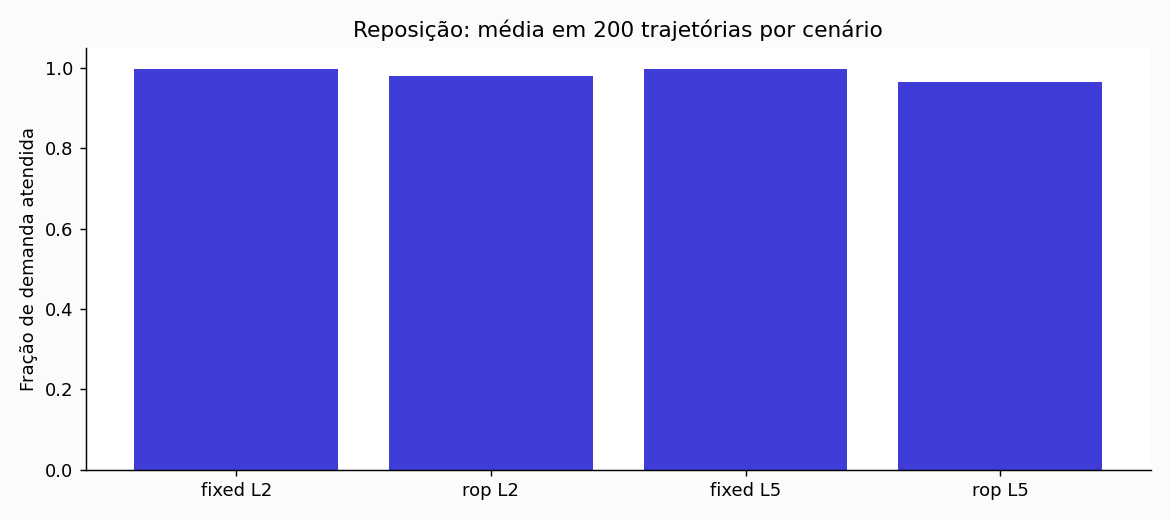

In [8]:
summary=pd.read_csv(outdir()/'simulation_summary.csv')
display(summary.round(4))
display(Image(filename=str(outdir()/'inventory.png')))

## Limites e próxima semana

Só leite, validade fixa, prazo fixo, sem capacidade e sem preço real. Os próximos sete dias abaixo são uma previsão depois do fim do histórico simulado, não uma compra para a data atual.

In [9]:
display(pd.read_csv(outdir()/'forecast_next7.csv'))

,date,item,predicted_units,milk_ml
0,2025-08-23,Cafe com leite,85.0,6800.0
1,2025-08-24,Cafe com leite,0.0,0.0
2,2025-08-25,Cafe com leite,60.0,4800.0
3,2025-08-26,Cafe com leite,59.0,4720.0
4,2025-08-27,Cafe com leite,54.0,4320.0
5,2025-08-28,Cafe com leite,69.0,5520.0
6,2025-08-29,Cafe com leite,74.0,5920.0
7,2025-08-23,Cappuccino,56.0,10080.0
8,2025-08-24,Cappuccino,0.0,0.0
9,2025-08-25,Cappuccino,27.0,4860.0


## Verificações e reprodução

Execute `python -m unittest discover -s tests -v` na raiz. Os requisitos de notebook são separados dos requisitos mínimos do pipeline. A saída deste arquivo é de execução local real; isso não significa que já rodou no Dell, no GitHub ou em produção. Consulte os créditos e as limitações antes de publicar.